# Random Sampling for Civil Engineering

Random sampling turns probability models into realizations that can be propagated through calculations. In civil engineering, Monte Carlo simulation uses those realizations to study uncertain loads, resistance, material properties, and measurement error. This notebook develops four ways to generate samples:

1. Inverse transform sampling
2. Acceptance-rejection sampling
3. The Box-Müller transform
4. The ziggurat method

In [1]:
%matplotlib inline
import logging
import time

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)
np.set_printoptions(precision=4, suppress=True)

print(f"NumPy {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy 2.3.5
Matplotlib 3.10.6


## 1. Inverse transform sampling

Let $U\sim\mathrm{Uniform}(0,1)$ and let $F_X$ be the CDF of the target random variable $X$. For a continuous target, define $X=F_X^{-1}(U)$. Then

$$P(X\le x)=P(F_X^{-1}(U)\le x)=P(U\le F_X(x))=F_X(x),$$

so $X$ has the desired distribution. For CDFs that are not continuous, use the generalized inverse $F_X^{-1}(u)=\inf\{x:F_X(x)\ge u\}$.

**Algorithm**
1. Draw $U$ uniformly from $(0,1)$.
2. Return $X=F_X^{-1}(U)$.
3. Repeat for the desired number of samples.

This method is useful when the inverse CDF is available in closed form. It is also useful for generating samples from a discrete distribution, where the generalized inverse is easy to compute. However, it can be impractical for distributions without a closed-form inverse, and tail probabilities can be sensitive to floating-point precision.

Let's illustrate this with an exponential distribution. The CDF of an exponential random variable with rate $\lambda>0$ is
$$
F_X(x) = 1 - e^{-\lambda x}, \quad x \ge 0.
$$
The mean and variance are $1/\lambda$ and $1/\lambda^2$, respectively.

So inversion gives $X=-\ln(1-U)/\lambda$. Since $1-U$ is also uniform, $-\ln(U)/\lambda$ is equivalent. Here $\lambda$ is the rate parameter, that is, the expected number of events per unit time. The exponential distribution is often used to model the time between events in a Poisson process, which is a common model for random arrivals of vehicles, customers, or other entities.

In [2]:
lamda     = 1.5   # events per hour
n_samples = 50_000

def sample_exponential_ITS(n_samples, lamda):
    # Keep U strictly positive because log(0) is undefined.(-inf)
    u = rng.uniform(np.nextafter(0.0, 1.0), 1.0, size=n_samples)   # U ~(0,1)
    samples_U = -np.log(u)/lamda
    return samples_U

samples = sample_exponential_ITS(n_samples, lamda)
print(f"Mean     = {np.mean(samples):.4f} (Theoretical mean     = {     1/lamda:.4f})  -> hours/event")
print(f"Variance = {np.var( samples):.4f} (Theoretical variance = {1/(lamda**2):.4f})  -> hours^2/event^2")

Mean     = 0.6661 (Theoretical mean     = 0.6667)  -> hours/event
Variance = 0.4496 (Theoretical variance = 0.4444)  -> hours^2/event^2


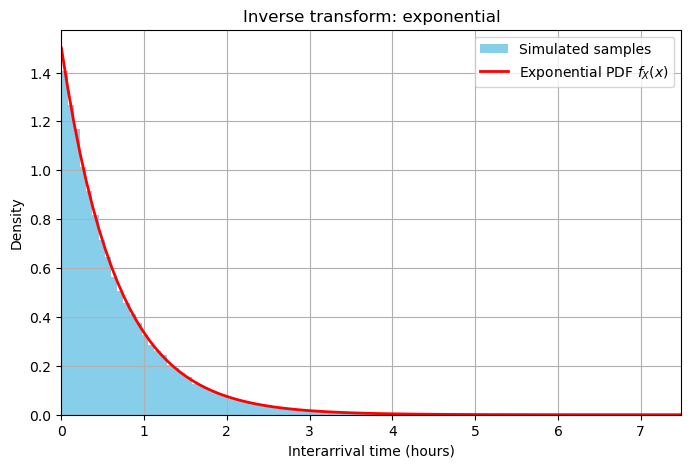

In [3]:
max_x = np.max(samples)   # np.quantile(samples, 0.999)
x = np.linspace(0.0, max_x, 100)
PDF_exponential = lamda * np.exp(-lamda * x)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(samples, bins=100, density=True, color="skyblue", label="Simulated samples")
ax.plot(x, PDF_exponential, lw=2,       color="red",     label="Exponential PDF $f_X(x)$")
ax.set_xlabel("Interarrival time (hours)")
ax.set_ylabel("Density")
ax.set_title("Inverse transform: exponential")
ax.set_xlim(0.0, max_x)
ax.grid()
ax.legend()
plt.show()

## 2. Acceptance-rejection sampling

Choose an easy-to-sample proposal density $g_X(x)$ and a constant $M$ such that $f_X(x)\le M g_X(x)$ everywhere. Draw $X$ from the proposal and $Y\sim\mathrm{Uniform}(0,Mg_X(X))$; accept $X$ when $Y\le f_X(X)$. The acceptance-rejection method is useful when the target distribution is difficult to sample from directly, but a suitable proposal distribution is available.

**Algorithm**
1. Draw a candidate $X$ from $g_X$.
2. Draw $V\sim\mathrm{Uniform}(0,1)$.
3. Accept $X$ if $V\le f_X(X)/(M g_X(X))$; otherwise reject it and try again.

$M$ should be chosen as small as possible to maximize the acceptance probability. However, if $M$ is too small, the condition $f_X(x)\le M g_X(x)$ may be violated, leading to biased samples.


 Let's illustrate this with a triangular distribution. The triangular distribution is defined by a lower limit $a$, an upper limit $b$, and a mode $c$ (the peak of the triangle). The PDF is given by:
$$
f_X(x) = \begin{cases}
\frac{2(x-a)}{(b-a)(c-a)}, & a \le x < c, \\
\frac{2(b-x)}{(b-a)(b-c)}, & c \le x \le b, \\
0, & \text{otherwise}.
\end{cases}
$$
Its mean and variance are $(a+b+c)/3$ and $(a^2+b^2+c^2-ab-ac-bc)/18$, respectively.

Acceptance-rejection: 50000 samples; mean=1.1648; variance=0.1789; acceptance rate=0.500


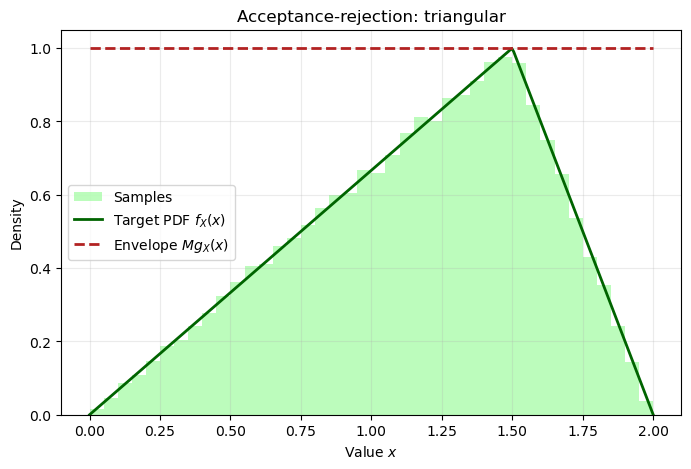

In [12]:
def f_X(x, a, b, c):
    """Triangular PDF with support [a, b] and mode c."""
    if not (a <= c <= b):
        raise ValueError("Mode c must be between a and b.")
    if a <= x < c:
        return 2 * (x - a) / ((b - a) * (c - a))
    elif c <= x <= b:
        return 2 * (b - x) / ((b - a) * (b - c))
    else:
        return 0.0


def g_X(x, a, b):
    """Uniform PDF with support [a, b]."""
    if a <= x <= b:
        return 1 / (b - a)
    else:
        return 0.0


a = 0.0
b = 2.0
c = 1.5
M = 2.0  # f_X(x) <= M * g_X(x)


def sample_triangular_ARM(n_samples, a, b, c):
    if n_samples <= 0:
        raise ValueError("n_samples must be positive")

    accepted_parts = []
    accepted_count = 0
    proposal_count = 0
    proposal_height = M * g_X(a, a, b)

    while accepted_count < n_samples:
        batch_size = max(1_024, 2 * (n_samples - accepted_count))
        x_proposal = rng.uniform(a, b, size=batch_size)
        y_proposal = rng.uniform(0.0, proposal_height, size=batch_size)
        target_pdf = np.array([f_X(x, a, b, c) for x in x_proposal])
        keep = y_proposal <= target_pdf
        accepted_count += int(np.count_nonzero(keep))
        proposal_count += batch_size
        accepted_parts.append(x_proposal[keep])

    values = np.concatenate(accepted_parts)[:n_samples]
    acceptance_rate = accepted_count / proposal_count
    print(
        f"Acceptance-rejection: {len(values)} samples; "
        f"mean={np.mean(values):.4f}; variance={np.var(values):.4f}; "
        f"acceptance rate={acceptance_rate:.3f}"
    )
    return values


triangle_samples = sample_triangular_ARM(n_samples, a, b, c)
triangle_x = np.linspace(a, b, 300)
triangle_pdf = np.array([f_X(x, a, b, c) for x in triangle_x])
proposal_envelope = np.array([M * g_X(x, a, b) for x in triangle_x])
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(triangle_samples, bins=40, range=(a, b), density=True, alpha=0.65, color="palegreen", label="Samples")
ax.plot(triangle_x, triangle_pdf, color="darkgreen", lw=2, label="Target PDF $f_X(x)$")
ax.plot(triangle_x, proposal_envelope, color="firebrick", ls="--", lw=2, label="Envelope $M g_X(x)$")
ax.set(xlabel="Value $x$", ylabel="Density", title="Acceptance-rejection: triangular")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 4.3 Box-Muller transform

For independent $Z_0,Z_1\sim N(0,1)$, the joint density is

$$f_{Z_0,Z_1}(z_0,z_1)=(2\pi)^{-1}\exp[-(z_0^2+z_1^2)/2].$$

In polar coordinates, the angle is uniform and the squared radius has an exponential tail. Thus, for independent $U_1,U_2\sim\mathrm{Uniform}(0,1)$,

$$R=\sqrt{-2\ln U_1},\qquad \Theta=2\pi U_2,$$
$$Z_0=R\cos\Theta,\qquad Z_1=R\sin\Theta.$$

Two uniforms produce a pair of independent standard normal values. With $U_1=0.25$ and $U_2=0.125$, $R=\sqrt{-2\ln(0.25)}\approx1.665$, $\Theta=\pi/4$, and $Z_0=Z_1\approx1.177$. Engineers can use these values to model normal measurement error or approximately normal material-property variation: for mean $\mu$ and standard deviation $\sigma$, set $X=\mu+\sigma Z$. Box-Muller is transparent and easy to vectorize, but uses logarithm, square root, sine, and cosine operations; values are naturally generated in pairs. Ensure $U_1>0$ to avoid $\ln(0)$.

Box-Muller: 50000 samples; mean=-0.0074; variance=1.0064


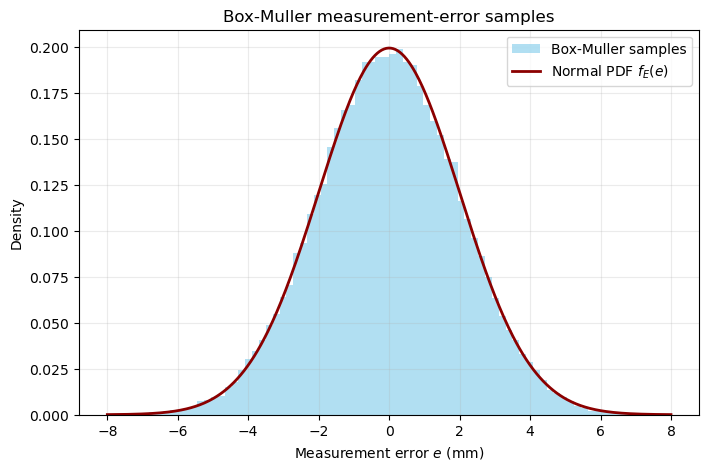

In [5]:
measurement_error_sd_mm = 2.0


def normal_pdf(x, mean, sd):
    return np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * np.sqrt(2.0 * np.pi))


def sample_box_muller(n_samples, rng):
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng must be a numpy.random.Generator")

    n_pairs = (n_samples + 1) // 2
    u1 = rng.uniform(np.nextafter(0.0, 1.0), 1.0, size=n_pairs)
    u2 = rng.uniform(0.0, 1.0, size=n_pairs)
    radius = np.sqrt(-2.0 * np.log(u1))
    angle = 2.0 * np.pi * u2
    z0 = radius * np.cos(angle)
    z1 = radius * np.sin(angle)
    values = np.column_stack((z0, z1)).ravel()[:n_samples]
    print(f"Box-Muller: {len(values)} samples; mean={np.mean(values):.4f}; variance={np.var(values):.4f}")
    return values


box_muller_samples = sample_box_muller(n_samples, rng)
measurement_errors = measurement_error_sd_mm * box_muller_samples
x_grid = np.linspace(-4.0 * measurement_error_sd_mm, 4.0 * measurement_error_sd_mm, 500)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(measurement_errors, bins=80, density=True, alpha=0.65, color="skyblue", label="Box-Muller samples")
ax.plot(x_grid, normal_pdf(x_grid, 0.0, measurement_error_sd_mm), color="darkred", lw=2, label="Normal PDF $f_E(e)$")
ax.set(xlabel="Measurement error $e$ (mm)", ylabel="Density", title="Box-Muller measurement-error samples")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### 4.4 Ziggurat method for Gaussian samples

The Ziggurat method covers the area under a density with stacked rectangles of equal area, plus a special tail region. A strip index and random coordinates identify a candidate. Most candidates fall in a rectangle fully beneath the density and can be accepted with a quick table comparison. Candidates in an overhang need a density test; the extreme tail uses a separate tail-sampling/rejection step. Choosing equal-area strips makes each region's selection probability match its area, and accepting only points below the density leaves points distributed proportionally to the target density.

**Conceptual algorithm**
1. Select a strip and sign using precomputed tables; draw a candidate horizontal coordinate.
2. If the candidate lies inside the strip's fully covered rectangle, accept immediately.
3. If it lies in an overhang, draw a vertical coordinate and accept only if it is below $f_Z(x)=\exp(-x^2/2)/\sqrt{2\pi}$.
4. If it is in the tail strip, use a tail-specific sampler and accept/reject test.
5. Repeat until a value is accepted.

For an overhang check at $x=0.8$, $f_Z(0.8)\approx0.290$. A vertical ordinate $y=0.20$ is below the curve, so the candidate is accepted. In applications, use a tested implementation: NumPy's current standard-normal generator uses Ziggurat sampling with a fast path and special rejection/tail paths ([implementation source](https://github.com/numpy/numpy/blob/main/numpy/random/src/distributions/distributions.c)). The table construction and bit-level stream are implementation details, and exact streams can vary with generator/software versions. The speed is valuable when large Monte Carlo reliability runs need many normal deviates; implementing tables and tail handling incorrectly can silently distort rare-event estimates.

Overhang check: f_Z(0.8)=0.290; y=0.20 -> accept
NumPy normal: 50000 samples; mean=400.0102; variance=1593.5172


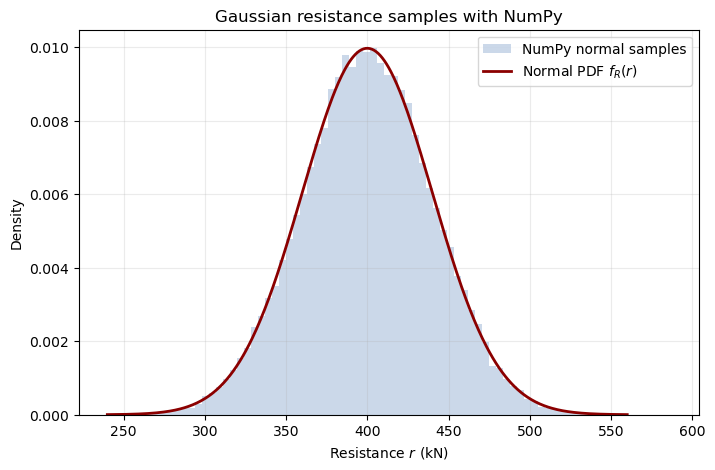

In [6]:
resistance_mean = 400.0
resistance_sd = 40.0

fz_at_08 = float(normal_pdf(np.array([0.8]), 0.0, 1.0)[0])
print(f"Overhang check: f_Z(0.8)={fz_at_08:.3f}; y=0.20 -> {'accept' if 0.20 < fz_at_08 else 'reject'}")
assert fz_at_08 > 0.20


def sample_normal_ziggurat(n_samples, mean, sd, rng):
    if not np.isfinite(mean):
        raise ValueError("mean must be finite")
    if not np.isfinite(sd) or sd <= 0:
        raise ValueError("sd must be finite and positive")
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng must be a numpy.random.Generator")

    values = mean + sd * rng.standard_normal(size=n_samples)
    print(f"NumPy normal: {len(values)} samples; mean={np.mean(values):.4f}; variance={np.var(values):.4f}")
    return values


ziggurat_resistance = sample_normal_ziggurat(
    n_samples, resistance_mean, resistance_sd, rng
)
x_grid = np.linspace(resistance_mean - 4 * resistance_sd, resistance_mean + 4 * resistance_sd, 500)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ziggurat_resistance, bins=80, density=True, alpha=0.65, color="lightsteelblue", label="NumPy normal samples")
ax.plot(x_grid, normal_pdf(x_grid, resistance_mean, resistance_sd), color="darkred", lw=2, label="Normal PDF $f_R(r)$")
ax.set(xlabel="Resistance $r$ (kN)", ylabel="Density", title="Gaussian resistance samples with NumPy")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 6. Estimate Reliability

Use the resistance samples generated in the Ziggurat example and generate independent load samples to estimate $P(S>R)$, the probability of failure under this simplified model. For an estimated failure fraction $\hat p$, the approximate Monte Carlo standard error is $\sqrt{\hat p(1-\hat p)/n}$. Rare failures require many more samples for a stable estimate.

In [7]:
load_mean = 300.0
load_sd = 50.0

load_samples = sample_normal_ziggurat(n_samples, load_mean, load_sd, rng)
failure = load_samples > ziggurat_resistance
failure_probability = float(np.mean(failure))
mc_standard_error = np.sqrt(failure_probability * (1.0 - failure_probability) / len(failure))
print(f"Estimated P(load > resistance) = {failure_probability:.4f}")
print(f"Approximate Monte Carlo standard error = {mc_standard_error:.4f}")
print(f"Based on {len(failure):,} independent load-resistance pairs")
print("Illustrative assumptions only; this is not a design check.")

NumPy normal: 50000 samples; mean=299.9161; variance=2508.3283
Estimated P(load > resistance) = 0.0591
Approximate Monte Carlo standard error = 0.0011
Based on 50,000 independent load-resistance pairs
Illustrative assumptions only; this is not a design check.


In [10]:
triangular_mean = (a + b + c) / 3
triangular_variance = (a**2 + b**2 + c**2 - a*b - a*c - b*c) / 18

print("\nMoment check (sample versus theory):")
print(
    f"Exponential mean: {np.mean(samples):.4f} versus {1 / lamda:.4f}; "
    f"variance: {np.var(samples):.4f} versus {1 / lamda**2:.4f}"
)
print(
    f"Triangular mean: {np.mean(triangle_samples):.4f} versus {triangular_mean:.4f}; "
    f"variance: {np.var(triangle_samples):.4f} versus {triangular_variance:.4f}"
)


Moment check (sample versus theory):
Exponential mean: 0.6661 versus 0.6667; variance: 0.4496 versus 0.4444
Triangular mean: 1.1668 versus 1.1667; variance: 0.1796 versus 0.1806


## 7. Write Unit Tests for Core Logic

These notebook assertions check deterministic calculations and statistical behavior. Statistical tests use tolerances rather than exact sample values: random samples fluctuate, but their moments should be close to theoretical targets at this sample size. The rejection sampler prints its observed acceptance rate for comparison with the theoretical value of 0.5.

In [11]:
n_test = 30_000
exp_test = sample_exponential_ITS(n_test, lamda)
triangle_test = sample_triangular_ARM(n_test, a, b, c)
box_test = sample_box_muller(n_test, rng)
ziggurat_test = sample_normal_ziggurat(n_test, 0.0, 1.0, rng)

# Distribution support and sample-count edge case.
assert len(sample_box_muller(5, rng)) == 5
assert np.all(exp_test > 0.0)
assert np.all((triangle_test >= a) & (triangle_test <= b))
assert all(np.all(np.isfinite(values)) for values in [exp_test, triangle_test, box_test, ziggurat_test])

# Exponential moments: mean=1/lambda and variance=1/lambda**2.
assert abs(np.mean(exp_test) - 1 / lamda) < 0.015
assert abs(np.var(exp_test) - 1 / lamda**2) < 0.035

# Triangular moments from the selected lower limit, upper limit, and mode.
assert abs(np.mean(triangle_test) - triangular_mean) < 0.012
assert abs(np.var(triangle_test) - triangular_variance) < 0.008

# Both standard-normal generators should have mean near 0 and variance near 1.
for normal_samples in [box_test, ziggurat_test]:
    assert abs(np.mean(normal_samples)) < 0.025
    assert abs(np.var(normal_samples) - 1.0) < 0.04

print("All core sampling assertions passed.")

Acceptance-rejection: 30000 samples; mean=1.1639; variance=0.1824; acceptance rate=0.501
Box-Muller: 30000 samples; mean=0.0052; variance=0.9963
NumPy normal: 30000 samples; mean=0.0061; variance=0.9947
Box-Muller: 5 samples; mean=0.0208; variance=0.1972
All core sampling assertions passed.


## 8. Add Debug Logging and Basic Performance Checks

A thin timing wrapper records method name, sample count, acceptance rate when applicable, and elapsed time. This makes the rejection sampler's extra proposal work visible and gives a simple first comparison. Timings depend on hardware, Python/NumPy versions, and workload; they are not universal rankings.

In [ ]:
logger = logging.getLogger("random_sampling_tutorial")
logger.setLevel(logging.INFO)
if not logger.handlers:
    handler = logging.StreamHandler()
    handler.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
    logger.addHandler(handler)


def timed_run(label, sampler, *args):
    start = time.perf_counter()
    samples = sampler(*args)
    elapsed = time.perf_counter() - start
    logger.info("%s: %s samples in %.4f s", label, len(samples), elapsed)
    return samples, elapsed


n_benchmark = 25_000
benchmarks = [
    ("Inverse transform", timed_run("Inverse transform", sample_exponential_inverse, n_benchmark, rate_per_hour, rng)),
    ("Acceptance-rejection", timed_run("Acceptance-rejection", sample_triangular_accept_reject, n_benchmark, rng)),
    ("Box-Muller", timed_run("Box-Muller", sample_box_muller, n_benchmark, rng)),
    ("NumPy Ziggurat normal", timed_run("NumPy Ziggurat normal", sample_normal_ziggurat, n_benchmark, 0.0, 1.0, rng)),
]
print("\nElapsed seconds:")
for label, (samples, elapsed) in benchmarks:
    print(f"{label:38s} {elapsed:.4f}")

## Choosing a Sampling Method

| Method | Strength | Good fit | Main cost or limitation |
|---|---|---|---|
| Inverse transform | Simple and direct; preserves the target CDF by construction | Distributions with an available, stable inverse CDF | An inverse may be unavailable or expensive; extreme-tail calculations can lose precision |
| Acceptance-rejection | Flexible; only needs a proposal and a valid envelope | Custom distributions with a convenient, close proposal | Efficiency is $1/M$; a loose envelope wastes draws and an invalid bound biases samples |
| Box-Muller | Clear construction; produces two standard normals from two uniforms | Teaching, moderate-size normal samples, or transparent implementations | Log, square root, sine, and cosine operations; generates results in pairs |
| Ziggurat | Fast common path for large numbers of normal samples | Large Monte Carlo runs using a trusted numerical library | Table setup and tail/rejection details are intricate; implementation streams may vary by version |

No sampler compensates for a poorly chosen probability model. Check the model, parameters, support, and sample diagnostics before using generated values in a design or reliability decision.

## Conclusion

Inverse transform is a natural choice when the CDF can be inverted, acceptance-rejection handles many targets through a proposal envelope, and Box-Muller and Ziggurat are specialized ways to generate Gaussian values. Box-Muller exposes the mathematics; Ziggurat is designed for a fast common path. In practice, choose the method that fits the target distribution and computational needs, validate the resulting samples, and use tested library implementations for production analyses.